In [1]:
import torch
from torch import nn

class MatrixFactorization(nn.Module):
    def __init__(self, n_users, n_movies, dim, global_mean):
        super().__init__()

        # user vectors
        self.user_vectors = nn.Embedding(n_users, dim)

        # movie vectors
        self.movie_vectors = nn.Embedding(n_movies, dim)

        # user biases
        self.user_biases = nn.Embedding(n_users, 1)
        
        # movie biases 
        self.movie_biases = nn.Embedding(n_movies, 1)

        self.global_mean = global_mean

        nn.init.normal_(self.user_vectors.weight, std=0.01)
        nn.init.normal_(self.movie_vectors.weight, std=0.01)
        nn.init.zeros_(self.user_biases.weight)
        nn.init.zeros_(self.movie_biases.weight)

    def forward(self, user_idx, movie_idx):
        u = self.user_vectors(user_idx)
        m = self.movie_vectors(movie_idx)

        dot = (u * m).sum(dim = 1)

        bu = self.user_biases(user_idx).squeeze(1)
        bm = self.movie_biases(movie_idx).squeeze(1)

        return self.global_mean + bu + bm + dot




In [2]:
# Load the Data
import pandas as pd

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

DATA = "../data/processed/ml-32m" # "../data/processed/ml-latest-small"
train = pd.read_csv(DATA + "/train.csv")


train_users = torch.tensor(train['user_idx'].values, device=device)
train_movies = torch.tensor(train['movie_idx'].values, device=device)
train_ratings = torch.tensor(train['rating'].values, dtype=torch.float32, device=device)

val = pd.read_csv(DATA + "/val.csv")

val_users = torch.tensor(val['user_idx'].values, device=device)
val_movies = torch.tensor(val['movie_idx'].values, device=device)
val_ratings = torch.tensor(val['rating'].values, dtype=torch.float32, device=device)

In [3]:
n_users = train['user_idx'].max() + 1
n_movies = train['movie_idx'].max() + 1
global_mean = train['rating'].mean()

# model = MatrixFactorization(n_users, n_movies, 50, global_mean)
# optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-5)

Training Hyper parameters

In [9]:
BATCH_SIZE = 65536
n = len(train_ratings)

def train_model(dim, lr, weight_decay, epochs=1000, patience=20):
    torch.manual_seed(0)
    # CHANGED: .to(device) moves the model's four tables to the GPU
    model = MatrixFactorization(n_users, n_movies, dim, global_mean).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val = float("inf")
    best_epoch = 0

    for epoch in range(epochs):
        order = torch.randperm(n, device=device)
        for start in range(0, n, BATCH_SIZE):
                idx = order[start:start + BATCH_SIZE]
        
                pred = model(train_users[idx], train_movies[idx])
                loss = ((pred - train_ratings[idx]) ** 2).mean()
        
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        
                #epoch_loss += loss.item()
                #n_batches += 1
        
        with torch.no_grad():
            val_pred = model(val_users, val_movies)
            val_mse = ((val_pred - val_ratings) ** 2).mean()

        if val_mse.item() < best_val:
            best_val = val_mse.item()
            best_epoch = epoch + 1
        
        elif epoch + 1 - best_epoch >= patience:
            break

    return best_val, best_epoch, model

In [15]:
LRS = [0.001, 0.003]
DIMS = [32, 64, 128]
WEIGHT_DECAYS = [3e-7, 3e-6]

runs = []
for lr in LRS:
    for dim in DIMS:
        for wd in WEIGHT_DECAYS:
            best_val, best_epoch, _ = train_model(dim=dim, lr=lr, weight_decay=wd)
            runs.append({"lr": lr, "dim": dim, "weight_decay": wd,
                         "best_val": best_val, "best_epoch": best_epoch})
            print(lr, dim, wd, round(best_val, 4), best_epoch)

best = min(runs, key=lambda r: r["best_val"])
print(best)


final_val, _, best_model = train_model(dim=best ["dim"], lr=best["lr"],
                                       weight_decay=best["weight_decay"],
                                       epochs=best["best_epoch"])
print("best_model validation MSE:", final_val)

0.001 32 3e-07 0.6991 9
0.001 32 3e-06 0.7214 17
0.001 64 3e-07 0.6925 7
0.001 64 3e-06 0.7183 14
0.001 128 3e-07 0.6879 5
0.001 128 3e-06 0.7172 12
0.003 32 3e-07 0.698 4
0.003 32 3e-06 0.723 76
0.003 64 3e-07 0.6928 3
0.003 64 3e-06 0.7231 113
0.003 128 3e-07 0.6941 2
0.003 128 3e-06 0.7251 76
{'lr': 0.001, 'dim': 128, 'weight_decay': 3e-07, 'best_val': 0.6878637671470642, 'best_epoch': 5}
best_model validation MSE: 0.6878637671470642


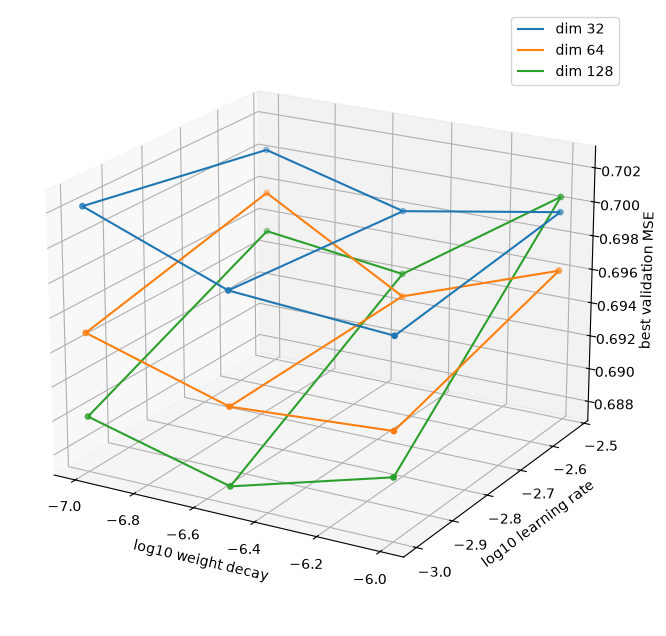

In [11]:
import numpy as np
import matplotlib.pyplot as plt

X, Y = np.meshgrid(np.log10(WEIGHT_DECAYS), np.log10(LRS))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

for dim, color in zip(DIMS, plt.cm.tab10.colors):
    Z = np.array([[next(r["best_val"] for r in runs
                        if r["dim"] == dim and r["lr"] == lr and r["weight_decay"] == wd)
                   for wd in WEIGHT_DECAYS] for lr in LRS])
    ax.plot_wireframe(X, Y, Z, color=color, label=f"dim {dim}")
    ax.scatter(X, Y, Z, color=color, s=15)

ax.set_xlabel("log10 weight decay")
ax.set_ylabel("log10 learning rate")
ax.set_zlabel("best validation MSE")
ax.legend()
ax.view_init(elev=20, azim=-60)
plt.show()

Final model

In [12]:
import copy

DIM = 128
LR = 0.001
WEIGHT_DECAY = 3e-7
MAX_EPOCHS = 20
PATIENCE = 20

torch.manual_seed(0)
final_model = MatrixFactorization(n_users, n_movies, DIM, global_mean).to(device)
optimizer = torch.optim.Adam(final_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

train_history = []
val_history = []
best_val = float("inf")
best_epoch = 0

for epoch in range(MAX_EPOCHS):
    order = torch.randperm(n, device=device)
    epoch_loss = 0.0
    n_batches = 0

    for start in range(0, n, BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]

        pred = final_model(train_users[idx], train_movies[idx])
        loss = ((pred - train_ratings[idx]) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    with torch.no_grad():
        val_pred = final_model(val_users, val_movies)
        val_mse = ((val_pred - val_ratings) ** 2).mean()
    
    train_history.append(epoch_loss / n_batches)
    val_history.append(val_mse.item())
    print(epoch + 1, round(train_history[-1], 4), round(val_history[-1], 4))

    if val_mse.item() < best_val:
        best_val = val_mse.item()
        best_epoch = epoch + 1
        best_state = copy.deepcopy(final_model.state_dict())
    # ADDED: stop once validation has gone PATIENCE epochs without improving
    elif epoch + 1 - best_epoch >= PATIENCE:
        break


final_model.load_state_dict(best_state)
print("best validation MSE:", best_val, "at epoch", best_epoch)

1 0.8223 0.7875
2 0.6269 0.7313
3 0.5646 0.7054
4 0.5148 0.6926
5 0.4692 0.6879
6 0.4273 0.6898
7 0.3911 0.6951
8 0.3619 0.7029
9 0.3392 0.7118
10 0.3217 0.7214
11 0.3081 0.7306
12 0.2974 0.7391
13 0.2887 0.7474
14 0.2816 0.7554
15 0.2756 0.7624
16 0.2705 0.7687
17 0.2661 0.7754
18 0.2624 0.7812
19 0.2591 0.7862
20 0.2562 0.7911
best validation MSE: 0.6878637671470642 at epoch 5


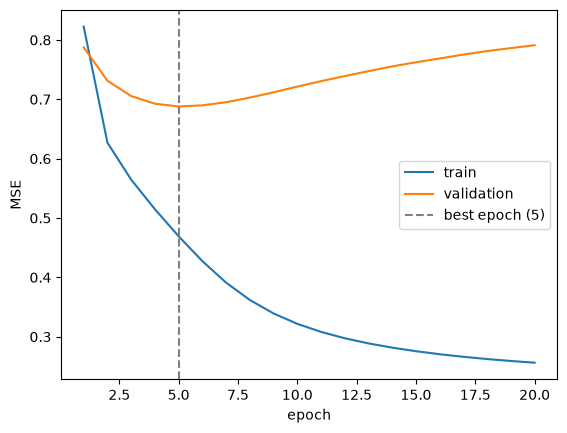

In [14]:
import matplotlib.pyplot as plt

epochs_run = range(1, len(train_history) + 1)

plt.plot(epochs_run, train_history, label="train")
plt.plot(epochs_run, val_history, label="validation")
# dashed line marks the epoch final_model was restored to
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [ ]:
MODEL_PATH = "../models/mf_32m.pt" # "../models/mf_small.pt"
torch.save(final_model.state_dict(), MODEL_PATH)
print("saved to", MODEL_PATH)

saved to ../models/mf_small.pt
